## Assigment 1
#### Programming in Python: Standard and External Library Packages D0040E 27043 HT2026
#### Inés Díaz

First, import libraries, load and explore the data:

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

In [22]:
# Load an explore the data
data = pd.read_csv("housing.csv", sep=',')
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


**1. How many geographical units are there in the dataset?**
I consider geographical units unique combinations of lat and len

In [23]:
unique_units = data[['longitude','latitude']].drop_duplicates() # get only lon and lat columns and remove duplicate rows
answer_1 = len(unique_units)
print(f'There are {answer_1} geographical units in the dataset.')

There are 12590 geographical units in the dataset.


**2. What is the mean house value among all “Ocean_proximity” categories?**

In [24]:
housev_mean = data[['median_house_value']].mean()
answer_2 = housev_mean.iloc[0].round(2)
print(f'The mean house value among all "Ocean proximity" categories is {answer_2}.')

The mean house value among all "Ocean proximity" categories is 206855.82.


**3. What is the mean house value in each “Ocean_proximity” category?**

In [25]:
answer_3 = data[['median_house_value', 'ocean_proximity']].groupby(['ocean_proximity']).mean().rename(columns={"median_house_value": "Mean (median) house value"})
print(f'The mean house values in each "Ocean proximity" categories are:\n{answer_3}')

The mean house values in each "Ocean proximity" categories are:
                 Mean (median) house value
ocean_proximity                           
<1H OCEAN                    240084.285464
INLAND                       124805.392001
ISLAND                       380440.000000
NEAR BAY                     259212.311790
NEAR OCEAN                   249433.977427


**4. What can you tell about the differences between the mean and median values?**


The median is less sensitive about outliers, as it is the middle value after sorting

**5. Create histograms for the following columns: “households”, “median_income”, “housing_median_age” and “median_house_value”.**

[[<Axes: title={'center': 'Households'}>
  <Axes: title={'center': 'Median income'}>]
 [<Axes: title={'center': 'Housing median age'}>
  <Axes: title={'center': 'Median house value'}>]]


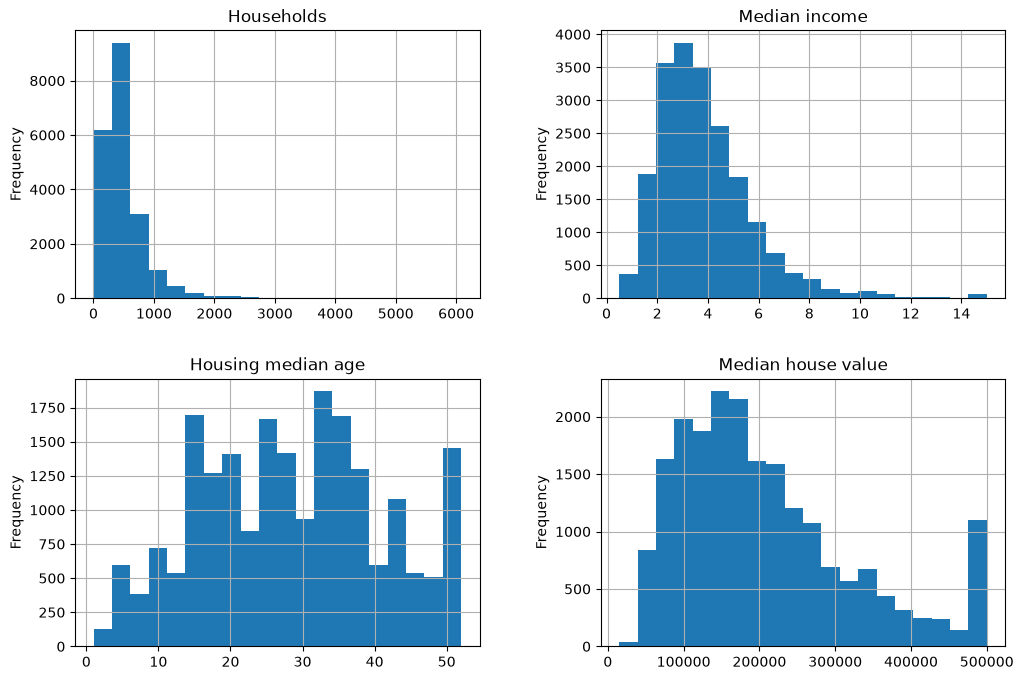

In [ ]:
data2 = data[['households', 'median_income', 'housing_median_age', 'median_house_value']].rename(columns={"households": "Households", "median_income": "Median income", "housing_median_age": "Housing median age", "median_house_value": "Median house value"})
axes = data2.hist(bins=20, figsize=(12, 8)) # I found that DataFrame.hist() "calls matplotlib.pyplot.hist() on each series of the df, resulting in one histogram per column" /https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html)
for ax in axes.flatten(): # the array obtained from data2.hist is 2x2, and .flatten() turns it into a 1
    ax.set_ylabel("Frequency")
plt.show()

**6. What can you highlight in these graphs? Specifically focus on end of the “housing_median_age” and “median_house_value” graphs. What do you think about the magnitude of the values in “median_house_value”?**